# Fraudulent Job Posting Detection
## 02 — Baseline Classification

### Objective

This notebook evaluates Bag of Words (BOW) and Term-Frequency Inverse Document-Frequency (TF-IDF) for identifying fraudulent job advertisements using only job descriptions.

Both will be evaluated using logistic regression and the same training/test split.

Since the dataset contains relatively few fraudulent postings the performance will be evaluated using precision, recall, F1 score, and confusion matrices instead of relying solely on accuracy

In [1]:
#notebook requirements
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [6]:
#mounts your google drive to grab the cleaned dataset from notebook1
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Use this section if you don't want to mount your google drive

#from google.colab import files

#uploaded = files.upload()

Saving fake_job_postings_cleaned.csv to fake_job_postings_cleaned.csv


In [8]:

#reads the cleaned dataset created in notebook 1
df = pd.read_csv('/content/drive/MyDrive/fake_job_postings_cleaned.csv')

#verifies the shape which should be (17880, 23)
print("Dataset shape:", df.shape)

df[['description_repaired', 'fraudulent']].head()

Dataset shape: (17880, 23)


,description_repaired,fraudulent
0,"Food52, a fast-growing, James Beard Award-winn...",0
1,Organised - Focused - Vibrant - Awesome! Do yo...,0
2,"Our client, located in Houston, is actively se...",0
3,THE COMPANY: ESRI – Environmental Systems Rese...,0
4,JOB TITLE: Itemization Review Manager LOCATION...,0


In [9]:
#grabs only the needed columns from the full dataset
baseline_df = df[
    ['job_id', 'description_repaired', 'fraudulent']
].copy()

#remove missing or empty descriptions
baseline_df = baseline_df.dropna(
    subset=['description_repaired']
)

#removes descriptions that contain only whitespace
baseline_df = baseline_df[
    baseline_df['description_repaired'].str.strip() != ''
].copy()

#displays the shape after empty descriptions are removed
print("Baseline dataset shape:", baseline_df.shape)

#displays the number of entries in each class: fraudulent, authentic
print("\nClass distribution:")
print(baseline_df['fraudulent'].value_counts())

baseline_df.head()

Baseline dataset shape: (17878, 3)

Class distribution:
fraudulent
0    17014
1      864
Name: count, dtype: int64


,job_id,description_repaired,fraudulent
0,1,"Food52, a fast-growing, James Beard Award-winn...",0
1,2,Organised - Focused - Vibrant - Awesome! Do yo...,0
2,3,"Our client, located in Houston, is actively se...",0
3,4,THE COMPANY: ESRI – Environmental Systems Rese...,0
4,5,JOB TITLE: Itemization Review Manager LOCATION...,0


In [10]:
#sets the repaired descriptions as in the input feature (x)
X = baseline_df['description_repaired']

#sets the fraudulent tag as the target label (y)
y = baseline_df['fraudulent']

#creates groups based on the repaired descriptions, most will be in their own group but identical descriptions belong to the same group. ensures that matching descriptions stay together and won't cause leakage
groups = baseline_df['description_repaired']

In [ ]:

#uses the scikit splitter to test different group splits and find the best version. n_split is how many candidates will be tested, test_size is what portion of the data will be separated for testing, random_state is seed
splitter = GroupShuffleSplit(
    n_splits=100,
    test_size=0.2,
    random_state=42
)

#finds the fraud rate for the whole dataset
overall_fraud_rate = y.mean()

#initializes variables for searching through the candidate splits
best_score = float('inf')
best_split = None

#performs the 100 split generations taking the assigned x, y, and groups from above. train_idx is the row positions assigned to train, test_idx is the row positions assigned to test. train_rate is the proportion of fraud in the train set, test_rate is the fraud proportion in the test set
for train_idx, test_idx in splitter.split(X, y, groups):
    train_rate = y.iloc[train_idx].mean()
    test_rate = y.iloc[test_idx].mean()

    test_fraction = len(test_idx) / len(y)

    #score the candidate split, the train_rate and test_rate should be as close to the overall rate as possible. Each portion should be close to 0 for an evenly assigned split.
    score = (
        abs(train_rate - overall_fraud_rate)
        + abs(test_rate - overall_fraud_rate)
        + abs(test_fraction - 0.20)
    )

    #overwrite if the score is closer to 0 than the best_score. Save the split if so
    if score < best_score:
        best_score = score
        best_split = (train_idx, test_idx)

#sets the final splits for further testing
train_idx, test_idx = best_split

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

#displays the details of the selected split
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining fraud rate:", round(y_train.mean() * 100, 2), "%")
print("Testing fraud rate:", round(y_test.mean() * 100, 2), "%")

print("\nOverlapping descriptions:",
      len(set(X_train).intersection(set(X_test))))

Training samples: 14274
Testing samples: 3604

Training fraud rate: 4.83 %
Testing fraud rate: 4.83 %

Overlapping descriptions: 0


In [ ]:
#determines if any descriptions are in both train and test set
overlap = set(X_train).intersection(set(X_test))

print("Descriptions appearing in both sets:", len(overlap))

Descriptions appearing in both sets: 0


In [ ]:
#displays the class distribution for training and test split
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training samples: 14274
Testing samples: 3604

Training class distribution:
fraudulent
0    95.166036
1     4.833964
Name: proportion, dtype: float64

Testing class distribution:
fraudulent
0    95.172031
1     4.827969
Name: proportion, dtype: float64


In [ ]:
#saves the best split to the drive for later use
split_assignments = pd.concat([
    baseline_df.iloc[train_idx][['job_id']].assign(split='train'),
    baseline_df.iloc[test_idx][['job_id']].assign(split='test')
])

split_assignments.to_csv(
    '/content/drive/MyDrive/job_posting_split.csv',
    index=False
)

In [ ]:
#sets up the BOW model using the sklearn pipeline
from sklearn.pipeline import Pipeline

#uses the countvectorizer, converts to lowercase, and does not remove stopwords, looks at individual words does not include bigrams yet
bow_model = Pipeline([
    ('vectorizer', CountVectorizer(
        lowercase=True,
        stop_words=None,
        ngram_range=(1, 1)
    )),
    #sets up the logistic classifier, up to 1000 iterations, class weight balanced keeps the minority class in mind since the fraudulent postings are rare, random_state is seed
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [ ]:
#trains the model we set up in previous step
bow_model.fit(X_train, y_train)

Pipeline(steps=[('vectorizer', CountVectorizer()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [ ]:
#generates predictions from the trained model and test data
y_pred_bow = bow_model.predict(X_test)

In [ ]:
#displays the outcome of the BOW model
print("Bag of Words + Logistic Regression")

print(classification_report(
    y_test,
    y_pred_bow,
    target_names=['Legitimate', 'Fraudulent'],
    digits=3
))

Bag of Words + Logistic Regression
              precision    recall  f1-score   support

  Legitimate      0.978     0.979     0.978      3430
  Fraudulent      0.577     0.557     0.567       174

    accuracy                          0.959      3604
   macro avg      0.777     0.768     0.773      3604
weighted avg      0.958     0.959     0.959      3604



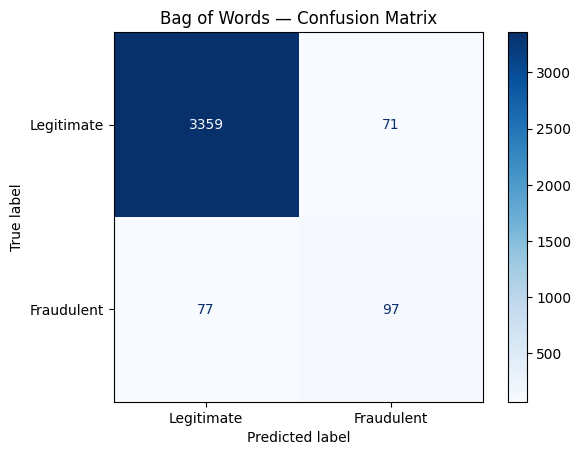

In [ ]:
#displays the confusion matrix from the BOW model
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bow,
    display_labels=['Legitimate', 'Fraudulent'],
    cmap='Blues',
    values_format='d'
)

plt.title('Bag of Words — Confusion Matrix')
plt.show()

TF-IDF + Logistic Regression
              precision    recall  f1-score   support

  Legitimate      0.986     0.965     0.975      3430
  Fraudulent      0.514     0.736     0.605       174

    accuracy                          0.954      3604
   macro avg      0.750     0.850     0.790      3604
weighted avg      0.963     0.954     0.958      3604



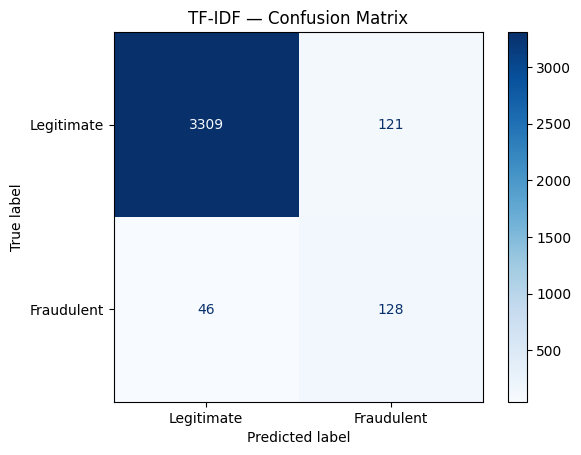

In [ ]:
#TF-IDF using logistic regression, parameters kept the same from the BOW wherever possible

tfidf_model = Pipeline([
    ('vectorizer', TfidfVectorizer(
        lowercase=True,
        stop_words=None,
        ngram_range=(1, 1)
    )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

#train the model
tfidf_model.fit(X_train, y_train)

#generate predictions
y_pred_tfidf = tfidf_model.predict(X_test)

#evaluate the model
print("TF-IDF + Logistic Regression")

print(classification_report(
    y_test,
    y_pred_tfidf,
    target_names=['Legitimate', 'Fraudulent'],
    digits=3
))

#display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tfidf,
    display_labels=['Legitimate', 'Fraudulent'],
    cmap='Blues',
    values_format='d'
)

plt.title('TF-IDF — Confusion Matrix')
plt.show()

In [ ]:
#use some built in metric tools from sklearn to display the results from BOW and TF-IDF
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    'Model': ['Bag of Words', 'TF-IDF'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_bow),
        accuracy_score(y_test, y_pred_tfidf)
    ],
    'Fraud Precision': [
        precision_score(y_test, y_pred_bow),
        precision_score(y_test, y_pred_tfidf)
    ],
    'Fraud Recall': [
        recall_score(y_test, y_pred_bow),
        recall_score(y_test, y_pred_tfidf)
    ],
    'Fraud F1': [
        f1_score(y_test, y_pred_bow),
        f1_score(y_test, y_pred_tfidf)
    ]
})

results.round(3)

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,Bag of Words,0.959,0.577,0.557,0.567
1,TF-IDF,0.954,0.514,0.736,0.605


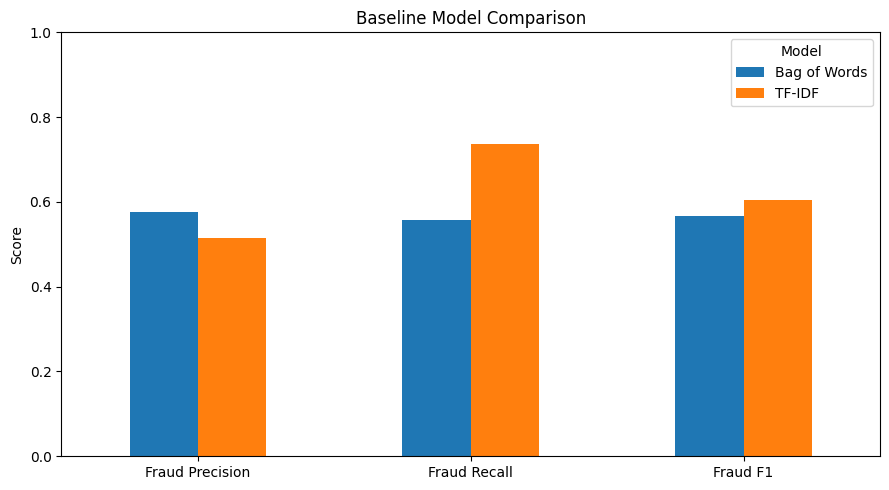

In [ ]:
#display a graph of the found metrics
results.set_index('Model')[
    ['Fraud Precision', 'Fraud Recall', 'Fraud F1']
].T.plot(
    kind='bar',
    figsize=(9, 5),
    rot=0
)

plt.title('Baseline Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

##Baseline Results

Two baseline models were tested using the repaired job descriptions, BOW and TF-IDF. Both models used the same split ensuring that the duplicate description was kept in the same split set. The models both used balanced class weights.

The BOW model achieved a fraud class precision of 0.577, recall of 0.557, and F1 score of 0.567. TF-IDF achieved a lower precision of 0.514 but a higher recall of 0.736 and F1 score of 0.605.

TF-IDF correctly identified 128 fraudulent postings compared with 97 for BOW. However, false positives increased from 71 to 121.

The results suggest TF-IDF is a better balance of precision and recall for detecting fraudulent postings with the current parameters. But both models show limitations and additional feature engineering or parameter tuning may improve outcomes.

In [ ]:
#uses the skleaern grid search and cross validation to test other parameters
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold
)

#configures the cross validation tool which splits the data into 5 folds, 4 folds are used for training while the 5th is used for validation
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#sets the train_groups to the x_train descriptions from the tarining data
train_groups = X_train

In [ ]:
#sets the BOW parameters that will be tested: it will look at unigrams (single words) and bigrams. The min_df is minimum document frequency where a word needs to appear before being included, it looks at 1 and 3. the classifier term controls the regularization: 0.1 , 1, and 10 are each tested
bow_param_grid = {
    'vectorizer__ngram_range': [(1, 1), (1, 2)],
    'vectorizer__min_df': [1, 3],
    'classifier__C': [0.1, 1, 10]
}

#sets the grid search, uses the bow_model and the create parametergrid, uses F1 score as the comparison, uses the cv stratifiedgroupfold, and displays progress
bow_search = GridSearchCV(
    estimator=bow_model,
    param_grid=bow_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

#executes the grid search
bow_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

#displays the outcome of the grid search and shows the parameters and score
print("Best BOW parameters:")
print(bow_search.best_params_)

print("\nBest cross-validation F1:")
print(round(bow_search.best_score_, 3))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best BOW parameters:
{'classifier__C': 0.1, 'vectorizer__min_df': 3, 'vectorizer__ngram_range': (1, 2)}

Best cross-validation F1:
0.611


In [ ]:
#repeats the entire grid search process for tf-idf
tfidf_param_grid = {
    'vectorizer__ngram_range': [(1, 1), (1, 2)],
    'vectorizer__min_df': [1, 3],
    'classifier__C': [0.1, 1, 10]
}

tfidf_search = GridSearchCV(
    estimator=tfidf_model,
    param_grid=tfidf_param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

tfidf_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("Best TF-IDF parameters:")
print(tfidf_search.best_params_)

print("\nBest cross-validation F1:")
print(round(tfidf_search.best_score_, 3))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best TF-IDF parameters:
{'classifier__C': 10, 'vectorizer__min_df': 3, 'vectorizer__ngram_range': (1, 2)}

Best cross-validation F1:
0.636


In [ ]:
#displays the outcome of the tuning process by showing the best F1 score and the parameters for both BOW and TF-IDF
tuning_results = pd.DataFrame({
    'Model': ['Bag of Words', 'TF-IDF'],
    'Best CV Fraud F1': [
        bow_search.best_score_,
        tfidf_search.best_score_
    ],
    'Best Parameters': [
        str(bow_search.best_params_),
        str(tfidf_search.best_params_)
    ]
})

tuning_results

,Model,Best CV Fraud F1,Best Parameters
0,Bag of Words,0.610736,"{'classifier__C': 0.1, 'vectorizer__min_df': 3..."
1,TF-IDF,0.636135,"{'classifier__C': 10, 'vectorizer__min_df': 3,..."


In [ ]:
#grabs the results from the 12 different parameter tests
bow_cv_results = pd.DataFrame(
    bow_search.cv_results_
)

tfidf_cv_results = pd.DataFrame(
    tfidf_search.cv_results_
)

#Displays the outcomes of each of the 12 runs for BOW
display(
    bow_cv_results[
        ['params', 'mean_test_score', 'std_test_score']
    ].sort_values(
        'mean_test_score',
        ascending=False
    )
)


,params,mean_test_score,std_test_score
3,"{'classifier__C': 0.1, 'vectorizer__min_df': 3...",0.610736,0.055906
9,"{'classifier__C': 10, 'vectorizer__min_df': 1,...",0.609238,0.063928
1,"{'classifier__C': 0.1, 'vectorizer__min_df': 1...",0.600374,0.063913
5,"{'classifier__C': 1, 'vectorizer__min_df': 1, ...",0.597310,0.075275
7,"{'classifier__C': 1, 'vectorizer__min_df': 3, ...",0.591183,0.058742
11,"{'classifier__C': 10, 'vectorizer__min_df': 3,...",0.577856,0.047363
0,"{'classifier__C': 0.1, 'vectorizer__min_df': 1...",0.568891,0.076921
2,"{'classifier__C': 0.1, 'vectorizer__min_df': 3...",0.566493,0.072872
6,"{'classifier__C': 1, 'vectorizer__min_df': 3, ...",0.565714,0.065746
4,"{'classifier__C': 1, 'vectorizer__min_df': 1, ...",0.560874,0.058408


In [ ]:
#displays the outcome of each of the 12 TF-IDF runs
display(
    tfidf_cv_results[
        ['params', 'mean_test_score', 'std_test_score']
    ].sort_values(
        'mean_test_score',
        ascending=False
    )
)

,params,mean_test_score,std_test_score
11,"{'classifier__C': 10, 'vectorizer__min_df': 3,...",0.636135,0.056278
9,"{'classifier__C': 10, 'vectorizer__min_df': 1,...",0.634305,0.058020
5,"{'classifier__C': 1, 'vectorizer__min_df': 1, ...",0.626520,0.058520
7,"{'classifier__C': 1, 'vectorizer__min_df': 3, ...",0.616773,0.058610
8,"{'classifier__C': 10, 'vectorizer__min_df': 1,...",0.595527,0.047484
10,"{'classifier__C': 10, 'vectorizer__min_df': 3,...",0.582714,0.044819
4,"{'classifier__C': 1, 'vectorizer__min_df': 1, ...",0.544738,0.072660
6,"{'classifier__C': 1, 'vectorizer__min_df': 3, ...",0.542505,0.069054
1,"{'classifier__C': 0.1, 'vectorizer__min_df': 1...",0.534402,0.076374
3,"{'classifier__C': 0.1, 'vectorizer__min_df': 3...",0.506227,0.042233


In [ ]:
from sklearn.model_selection import cross_validate

#evaluate the original Bag of Words configuration
bow_original_cv = cross_validate(
    bow_model,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

#evaluate the original TF-IDF configuration
tfidf_original_cv = cross_validate(
    tfidf_model,
    X_train,
    y_train,
    groups=train_groups,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

#diplays the original and tuned versions of both BOW and TF-IDF
cv_comparison = pd.DataFrame({
    'Model': [
        'BOW - Original',
        'BOW - Tuned',
        'TF-IDF - Original',
        'TF-IDF - Tuned'
    ],
    'Mean CV Fraud F1': [
        bow_original_cv['test_score'].mean(),
        bow_search.best_score_,
        tfidf_original_cv['test_score'].mean(),
        tfidf_search.best_score_
    ],
    'Std CV Fraud F1': [
        bow_original_cv['test_score'].std(),
        bow_search.cv_results_['std_test_score'][bow_search.best_index_],
        tfidf_original_cv['test_score'].std(),
        tfidf_search.cv_results_['std_test_score'][tfidf_search.best_index_]
    ]
})

display(cv_comparison.round(3))

,Model,Mean CV Fraud F1,Std CV Fraud F1
0,BOW - Original,0.561,0.058
1,BOW - Tuned,0.611,0.056
2,TF-IDF - Original,0.545,0.073
3,TF-IDF - Tuned,0.636,0.056


In [ ]:
#predictions from the tuned models
y_pred_bow_tuned = bow_search.predict(X_test)
y_pred_tfidf_tuned = tfidf_search.predict(X_test)

print("Tuned Bag of Words")
print(classification_report(
    y_test,
    y_pred_bow_tuned,
    target_names=['Legitimate', 'Fraudulent'],
    digits=3
))

print("\nTuned TF-IDF")
print(classification_report(
    y_test,
    y_pred_tfidf_tuned,
    target_names=['Legitimate', 'Fraudulent'],
    digits=3
))

Tuned Bag of Words
              precision    recall  f1-score   support

  Legitimate      0.984     0.986     0.985      3430
  Fraudulent      0.713     0.684     0.698       174

    accuracy                          0.971      3604
   macro avg      0.848     0.835     0.841      3604
weighted avg      0.971     0.971     0.971      3604


Tuned TF-IDF
              precision    recall  f1-score   support

  Legitimate      0.983     0.990     0.986      3430
  Fraudulent      0.760     0.655     0.704       174

    accuracy                          0.973      3604
   macro avg      0.871     0.822     0.845      3604
weighted avg      0.972     0.973     0.972      3604



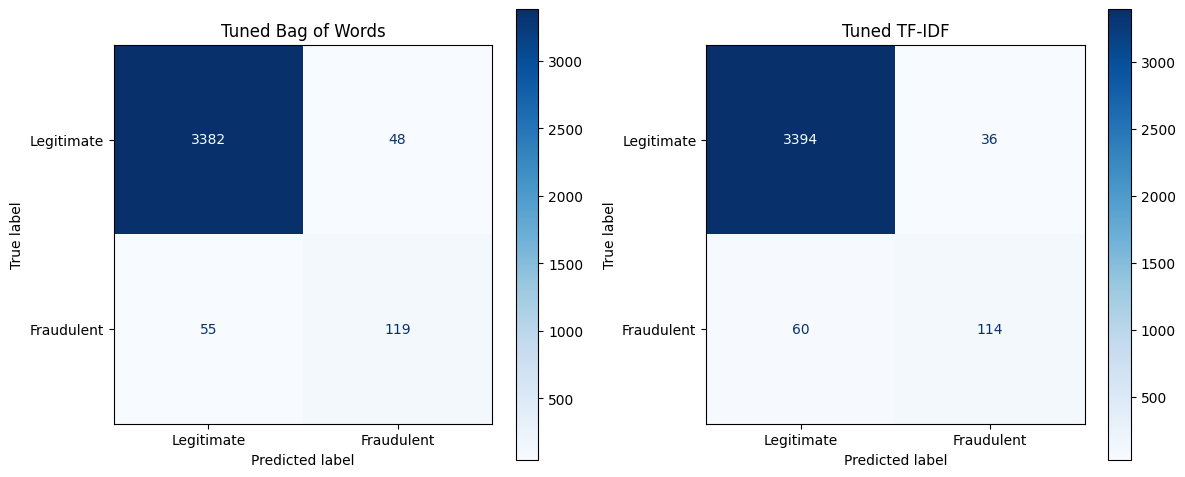

In [ ]:
#displays the confusion matrices from the tuned versions of both models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_bow_tuned,
    display_labels=['Legitimate', 'Fraudulent'],
    cmap='Blues',
    values_format='d',
    ax=axes[0]
)

axes[0].set_title('Tuned Bag of Words')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tfidf_tuned,
    display_labels=['Legitimate', 'Fraudulent'],
    cmap='Blues',
    values_format='d',
    ax=axes[1]
)

axes[1].set_title('Tuned TF-IDF')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

predictions = {
    'BOW - Original': y_pred_bow,
    'BOW - Tuned': y_pred_bow_tuned,
    'TF-IDF - Original': y_pred_tfidf,
    'TF-IDF - Tuned': y_pred_tfidf_tuned
}

comparison_rows = []

for model_name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Fraud Precision': precision_score(y_test, y_pred),
        'Fraud Recall': recall_score(y_test, y_pred),
        'Fraud F1': f1_score(y_test, y_pred),
        'False Positives': fp,
        'False Negatives': fn
    })

final_comparison = pd.DataFrame(comparison_rows)

display(final_comparison.round(3))

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,False Positives,False Negatives
0,BOW - Original,0.959,0.577,0.557,0.567,71,77
1,BOW - Tuned,0.971,0.713,0.684,0.698,48,55
2,TF-IDF - Original,0.954,0.514,0.736,0.605,121,46
3,TF-IDF - Tuned,0.973,0.760,0.655,0.704,36,60


In [ ]:
#saves the tuned models to the mounted drive
import joblib

joblib.dump(
    bow_search.best_estimator_,
    '/content/drive/MyDrive/bow_tuned_model.joblib'
)

joblib.dump(
    tfidf_search.best_estimator_,
    '/content/drive/MyDrive/tfidf_tuned_model.joblib'
)

['/content/drive/MyDrive/tfidf_tuned_model.joblib']

##Conclusion

The notebook evaluated BOW and TF-IDF text representations for detecting fraudulent job postings. Both models were trained using repaired job descriptions and both utilized the same train and test split.

The baseline models achieved fraudulent class F1 scores of 0.567 for BOW and 0.605 for TF-IDF. Tuning was performed using 5 fold cross validation to look at the impact of regularization, minimum document frequency, and n-gram range.

Both tuned models selected unigram and bigram features with a min document frequency of 3. The tuned BOW model achieved a test F1 score of 0.698 while the tuned TF-IDF achieved 0.704.

The tuned BOW model detected 119 of 174 fraudulent postings, compared with 114 for the tuned TF-IDF. However, TF-IDF produced fewer false positives and had a higher precision.

This shows that job descriptions alone contain useful information for detecting fraud but neither identified all the fraudulent postings. It also shows the tradeoff between precision and recall